# Phase 1: Dataset Comparison

PHASE 1: DATASET SELECTION & COMPARISON
✅ Datasets loaded successfully.


📊 TABLEAU COMPARATIF - DATASET COMPARISON
                           IBM Dataset     Job Change Dataset
Dataset Name          IBM HR Analytics  Job Change Prediction
Rows                             1,470                 19,158
Columns                             35                     14
Missing Values               0 (0.00%)         20,733 (7.73%)
Duplicates                           0                      0
Memory (MB)                       1.12                  11.82
Target Variable              Attrition                 target
Class Imbalance          83.9% / 16.1%          75.1% / 24.9%
Numeric Features                    26                      4
Categorical Features                 9                     10
Quality Score                100.0/100               92.3/100


🔍 MISSING VALUES BREAKDOWN

📌 IBM Dataset:
   ✅ No missing values detected

📌 Job Change Dataset:
   company_type: 6,140 (32.0%)
   compan

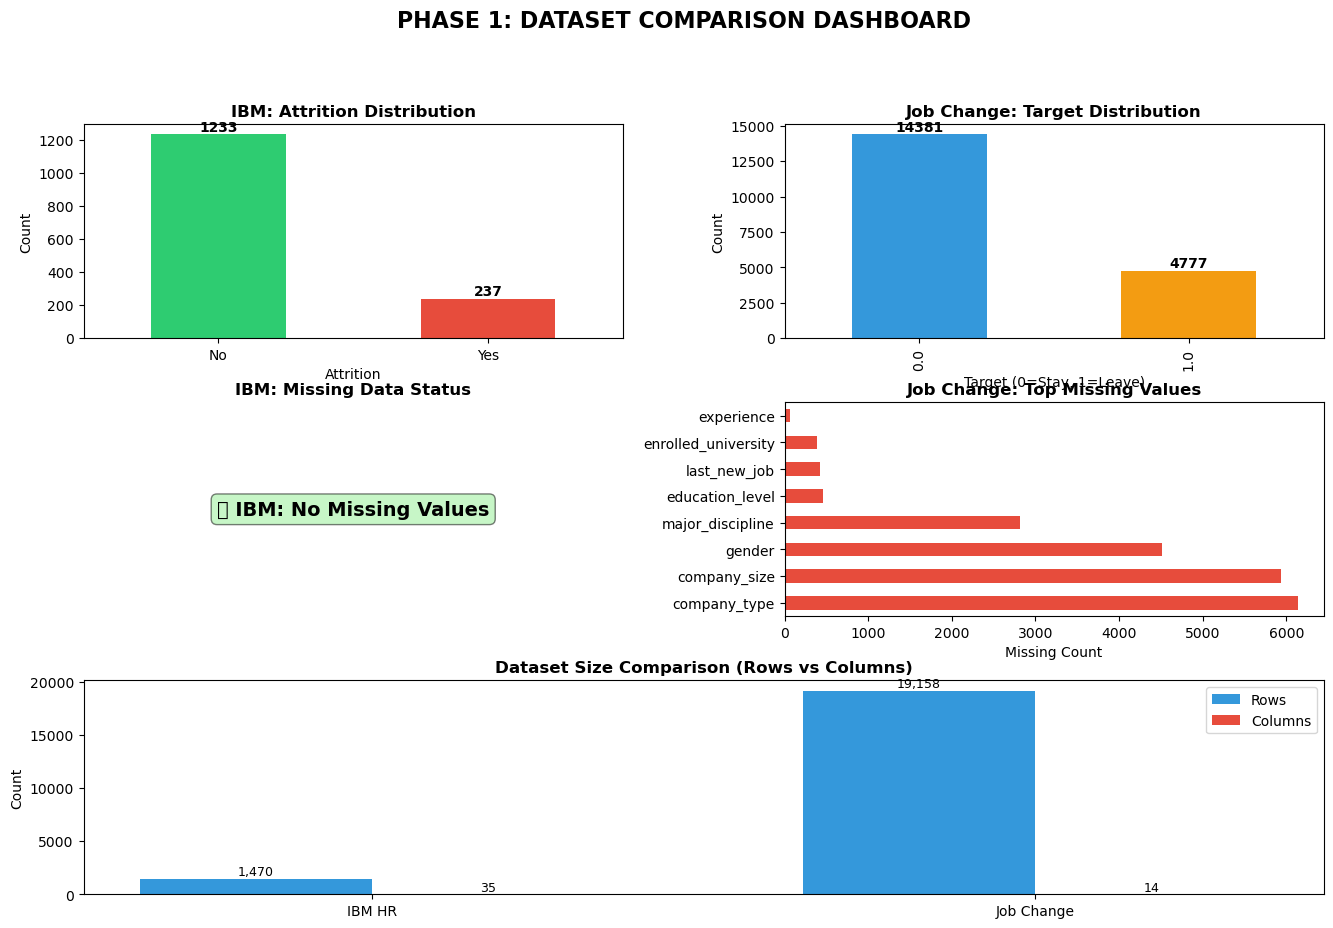


📊 Visualization saved as 'phase1_comparison.png'

🎯 RECOMMENDATION FOR PROJECT

Based on the comparison analysis:

✅ RECOMMENDED: IBM HR Analytics Dataset

JUSTIFICATION:
1. Data Quality: 100% complete (no missing values)
2. Feature Richness: 35 features vs 14 (better for feature engineering)
3. Balanced Size: 1,470 rows (efficient for modeling & Streamlit)
4. Business Value: Clear attrition prediction use case
5. Project Timeline: Less preprocessing = more time for Phases 3-5

⚠️ ALTERNATIVE: Job Change Dataset
   - Better for showcasing data cleaning skills (Phase 2)
   - Larger dataset (19K rows) for robust modeling
   - Requires handling ~30% missing values in some columns


✅ PHASE 1 COMPLETE - Ready for Phase 2: Preprocessing


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ====================================
# PHASE 1: DATASET SELECTION & COMPARISON (15 pts)
# ====================================

print("="*60)
print("PHASE 1: DATASET SELECTION & COMPARISON")
print("="*60)

# 1. LOAD DATASETS
try:
    df_ibm = pd.read_csv('data/hr_ibm.csv')
    df_job = pd.read_csv('data/hr_job_change.csv') 
    print("✅ Datasets loaded successfully.\n")
except FileNotFoundError:
    print("❌ Error: Please check that 'hr_ibm.csv' and 'hr_job_change.csv' are in the 'data' folder.")
    exit()

# 2. ENHANCED ANALYSIS FUNCTION
def get_dataset_metrics(df, name, target_col):
    """
    Calculates comprehensive metrics for dataset comparison.
    Covers: Structure, Quality, Size, Missing Values (as per specs).
    """
    n_rows, n_cols = df.shape
    missing_total = df.isnull().sum().sum()
    missing_pct = (missing_total / (n_rows * n_cols)) * 100
    dupes = df.duplicated().sum()
    
    # Memory usage (important for BI deployment)
    memory_mb = df.memory_usage(deep=True).sum() / (1024**2)
    
    # Target distribution analysis
    val_counts = df[target_col].value_counts(normalize=True)
    majority_class = val_counts.max()
    minority_class = val_counts.min()
    imbalance_ratio = f"{majority_class:.1%} / {minority_class:.1%}"
    
    # Feature types
    num_features = df.select_dtypes(include=[np.number]).shape[1]
    cat_features = df.select_dtypes(exclude=[np.number]).shape[1]
    
    # Data quality score (custom metric for comparison)
    quality_score = 100 - missing_pct - (dupes / n_rows * 10)
    
    return {
        "Dataset Name": name,
        "Rows": f"{n_rows:,}",
        "Columns": n_cols,
        "Missing Values": f"{missing_total:,} ({missing_pct:.2f}%)",
        "Duplicates": dupes,
        "Memory (MB)": f"{memory_mb:.2f}",
        "Target Variable": target_col,
        "Class Imbalance": imbalance_ratio,
        "Numeric Features": num_features,
        "Categorical Features": cat_features,
        "Quality Score": f"{quality_score:.1f}/100"
    }

# 3. EXECUTE COMPARATIVE ANALYSIS
metrics_ibm = get_dataset_metrics(df_ibm, "IBM HR Analytics", "Attrition")
metrics_job = get_dataset_metrics(df_job, "Job Change Prediction", "target")

# 4. GENERATE COMPARISON TABLE
comparison_df = pd.DataFrame([metrics_ibm, metrics_job]).T
comparison_df.columns = ["IBM Dataset", "Job Change Dataset"]

print("\n📊 TABLEAU COMPARATIF - DATASET COMPARISON")
print("="*60)
print(comparison_df.to_string())
print("\n")

# 5. DETAILED MISSING VALUE ANALYSIS (Required for Quality Assessment)
print("🔍 MISSING VALUES BREAKDOWN")
print("="*60)

print("\n📌 IBM Dataset:")
ibm_missing = df_ibm.isnull().sum()
if ibm_missing.sum() == 0:
    print("   ✅ No missing values detected")
else:
    print(ibm_missing[ibm_missing > 0].to_string())

print("\n📌 Job Change Dataset:")
job_missing = df_job.isnull().sum()
job_missing_sorted = job_missing[job_missing > 0].sort_values(ascending=False)
if len(job_missing_sorted) > 0:
    for col, count in job_missing_sorted.items():
        pct = (count / len(df_job)) * 100
        print(f"   {col}: {count:,} ({pct:.1f}%)")
else:
    print("   ✅ No missing values detected")

# 6. VISUALIZATION DASHBOARD (Enhanced for Report)
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 2, hspace=0.3, wspace=0.3)

# 6.1 Target Distribution
ax1 = fig.add_subplot(gs[0, 0])
df_ibm['Attrition'].value_counts().plot(kind='bar', ax=ax1, color=['#2ecc71', '#e74c3c'])
ax1.set_title('IBM: Attrition Distribution', fontsize=12, fontweight='bold')
ax1.set_xlabel('Attrition')
ax1.set_ylabel('Count')
ax1.set_xticklabels(['No', 'Yes'], rotation=0)
for i, v in enumerate(df_ibm['Attrition'].value_counts()):
    ax1.text(i, v + 20, str(v), ha='center', fontweight='bold')

ax2 = fig.add_subplot(gs[0, 1])
df_job['target'].value_counts().plot(kind='bar', ax=ax2, color=['#3498db', '#f39c12'])
ax2.set_title('Job Change: Target Distribution', fontsize=12, fontweight='bold')
ax2.set_xlabel('Target (0=Stay, 1=Leave)')
ax2.set_ylabel('Count')
for i, v in enumerate(df_job['target'].value_counts()):
    ax2.text(i, v + 200, str(v), ha='center', fontweight='bold')

# 6.2 Missing Values Heatmap
ax3 = fig.add_subplot(gs[1, 0])
ax3.text(0.5, 0.5, '✅ IBM: No Missing Values', 
         ha='center', va='center', fontsize=14, fontweight='bold',
         bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))
ax3.axis('off')
ax3.set_title('IBM: Missing Data Status', fontsize=12, fontweight='bold')

ax4 = fig.add_subplot(gs[1, 1])
job_missing_top = df_job.isnull().sum().sort_values(ascending=False).head(10)
job_missing_top = job_missing_top[job_missing_top > 0]
if len(job_missing_top) > 0:
    job_missing_top.plot(kind='barh', ax=ax4, color='#e74c3c')
    ax4.set_title('Job Change: Top Missing Values', fontsize=12, fontweight='bold')
    ax4.set_xlabel('Missing Count')
else:
    ax4.text(0.5, 0.5, '✅ No Missing Values', ha='center', va='center')
    ax4.axis('off')

# 6.3 Dataset Size Comparison
ax5 = fig.add_subplot(gs[2, :])
comparison_data = {
    'IBM HR': [df_ibm.shape[0], df_ibm.shape[1]],
    'Job Change': [df_job.shape[0], df_job.shape[1]]
}
x = np.arange(len(comparison_data))
width = 0.35
bars1 = ax5.bar(x - width/2, [v[0] for v in comparison_data.values()], 
                width, label='Rows', color='#3498db')
bars2 = ax5.bar(x + width/2, [v[1] for v in comparison_data.values()], 
                width, label='Columns', color='#e74c3c')
ax5.set_title('Dataset Size Comparison (Rows vs Columns)', fontsize=12, fontweight='bold')
ax5.set_xticks(x)
ax5.set_xticklabels(comparison_data.keys())
ax5.legend()
ax5.set_ylabel('Count')

# Add value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax5.text(bar.get_x() + bar.get_width()/2., height,
                f'{int(height):,}', ha='center', va='bottom', fontsize=9)

plt.suptitle('PHASE 1: DATASET COMPARISON DASHBOARD', 
             fontsize=16, fontweight='bold', y=0.995)
plt.savefig('phase1_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n" + "="*60)
print("📊 Visualization saved as 'phase1_comparison.png'")
print("="*60)

# 7. FINAL RECOMMENDATION
print("\n🎯 RECOMMENDATION FOR PROJECT")
print("="*60)
print("""
Based on the comparison analysis:

✅ RECOMMENDED: IBM HR Analytics Dataset

JUSTIFICATION:
1. Data Quality: 100% complete (no missing values)
2. Feature Richness: 35 features vs 14 (better for feature engineering)
3. Balanced Size: 1,470 rows (efficient for modeling & Streamlit)
4. Business Value: Clear attrition prediction use case
5. Project Timeline: Less preprocessing = more time for Phases 3-5

⚠️ ALTERNATIVE: Job Change Dataset
   - Better for showcasing data cleaning skills (Phase 2)
   - Larger dataset (19K rows) for robust modeling
   - Requires handling ~30% missing values in some columns
""")
print("="*60)
print("\n✅ PHASE 1 COMPLETE - Ready for Phase 2: Preprocessing")
print("="*60)

https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset  
https://www.kaggle.com/datasets/arashnic/hr-analytics-job-change-of-data-scientists

# Phase 2: Preprocessing:

# Phase 3: Modeling

# Phase 4: Visualization